# حباب سکه: سکه امامی چقدر بالاتر از ارزش طلای خودش معامله می‌شود؟

**آموزشی است و توصیه سرمایه‌گذاری نیست.** این نوت‌بوک چیزی را پیش‌بینی نمی‌کند و پیشنهاد خرید یا فروش ندارد. فقط یک سؤال اندازه‌گیری را جواب می‌دهد.

**ایده:** یک سکه امامی ۸٫۱۳۳ گرم وزن و عیار ۹۰۰ دارد، یعنی حدود ۷٫۳۲ گرم طلای خالص. پس «ارزش ذاتی» آن را از سه عدد می‌شود ساخت:

`ارزش ذاتی (ریال) = قیمت اونس (دلار) ÷ ۳۱٫۱۰۳۵ × ۷٫۳۲ × نرخ دلار (ریال)`

اختلاف قیمت بازار با این عدد را **حباب** (پریمیوم نسبت به ارزش ذاتی) می‌نامیم:

`حباب = قیمت سکه ÷ ارزش ذاتی − ۱`

**داده:** TGJU (tgju.org)، یک سایت اطلاع‌رسانی. منبع رسمی نیست؛ قبل از هر نتیجه‌گیری داده را وارسی و با منبع دوم مقایسه می‌کنیم. برای گرفتن داده: `python3 scripts/fetch_data.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, urllib.request
from pathlib import Path

# Data is not stored in the repository: it is downloaded from TGJU the first time.
ROOT = Path("..") if Path("../scripts/fetch_data.py").exists() else Path(".")  # repo checkout or Colab
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
(ROOT / "images").mkdir(exist_ok=True)
TGJU = {"ons_usd": "ons", "usd_irr": "price_dollar_rl", "emami_coin_irr": "sekee"}

def download(name):
    url = f"https://api.tgju.org/v1/market/indicator/summary-table-data/{TGJU[name]}"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    rows = json.load(urllib.request.urlopen(req, timeout=60))["data"]
    num = lambda t: float(t.replace(",", ""))
    # each row: open, low, high, close, change, change%, gregorian date, jalali date
    out = pd.DataFrame([(r[6].replace("/", "-"), *map(num, r[:4])) for r in rows],
                       columns=["date", "open", "low", "high", "close"]).sort_values("date")
    out.to_csv(DATA / f"{name}.csv", index=False)

def load(name):
    if not (DATA / f"{name}.csv").exists():
        download(name)
    return pd.read_csv(DATA / f"{name}.csv", parse_dates=["date"]).set_index("date")

ons, usd, coin = load("ons_usd"), load("usd_irr"), load("emami_coin_irr")
for name, d in [("ons (USD/oz)", ons), ("dollar (rial)", usd), ("emami coin (rial)", coin)]:
    print(f"{name:18s} {len(d):6d} rows  {d.index[0].date()} to {d.index[-1].date()}")

ons (USD/oz)        12168 rows  1979-12-26 to 2026-10-16
dollar (rial)        3978 rows  2011-11-26 to 2026-10-15
emami coin (rial)    4316 rows  2010-04-04 to 2026-10-15


## ۱. وارسی داده

سه چیز را چک می‌کنیم: تاریخ تکراری، قیمت صفر یا منفی، و پرش‌های روزانه غیرعادی.

In [2]:
for name, d in [("ons", ons), ("dollar", usd), ("coin", coin)]:
    r = np.log(d.close).diff()
    print(name, "| duplicate dates:", d.index.duplicated().sum(),
          "| non-positive prices:", (d.close <= 0).sum(),
          "| largest daily move:", f"{r.abs().max():.1%} on {r.abs().idxmax().date()}")

ons | duplicate dates: 0 | non-positive prices: 0 | largest daily move: 12.9% on 1983-02-28
dollar | duplicate dates: 0 | non-positive prices: 0 | largest daily move: 17.8% on 2018-04-17
coin | duplicate dates: 0 | non-positive prices: 0 | largest daily move: 18.8% on 2012-01-22


هیچ تکراری یا قیمت نامعتبری نیست و بزرگ‌ترین پرش‌ها قابل‌باورند (مثلاً جهش دلار در فروردین ۱۳۹۷؛ بقیه پرش‌ها را با رویداد مشخصی تطبیق نداده‌ایم). پس داده برای این مطالعه قابل‌استفاده است، ولی برای اطمینان بیشتر آن را با منبع دوم مقایسه می‌کنیم (پایین‌تر).

### منبع دوم
`python3 scripts/verify_data.py` سری‌ها را با دو منبع مستقل مقایسه می‌کند: قیمت طلا با آتی COMEX از Yahoo Finance (کل تاریخچه) و دلار و سکه با bon-bast.com (نمونه تصادفی ۸ تاریخ در هر سال؛ تاریخچه آن فقط از خرداد ۱۴۰۰ شروع می‌شود).

In [3]:
if not (DATA / "check_gold_yahoo.csv").exists():
    print("Not in the repository: run scripts/verify_data.py to reproduce this check (results are described below).")
else:
    g = pd.read_csv(DATA / "check_gold_yahoo.csv", index_col=0, parse_dates=True)
    rg = np.log(g[["tgju", "yahoo"]]).diff().dropna()
    print(f"GOLD  {len(g)} overlapping days: futures/TGJU - 1 has mean {g.ratio.mean():+.2%}, "
          f"95% of days within {g.ratio.abs().quantile(.95):.2%}; daily-return correlation {rg.tgju.corr(rg.yahoo):.3f}")
    b = pd.read_csv(DATA / "check_bonbast.csv", index_col=0, parse_dates=True)
    print(f"IRAN  {len(b)} sampled dates, 2021-06 to 2026")
    for k in ["usd_diff", "coin_diff"]:
        print(f"  {k}: median {b[k].median():+.2%}, within 3%: {(b[k].abs() < .03).mean():.0%} of dates, worst {b[k].abs().max():.1%} on {b[k].abs().idxmax().date()}")
    display(b.loc[b.usd_diff.abs().nlargest(1).index, ["tgju_usd", "bb_usd_sell", "bb_usd_buy", "tgju_coin", "bb_coin_sell", "bb_coin_buy"]])

GOLD  6554 overlapping days: futures/TGJU - 1 has mean +0.06%, 95% of days within 0.96%; daily-return correlation 0.905
IRAN  48 sampled dates, 2021-06 to 2026
  usd_diff: median +0.39%, within 3%: 98% of dates, worst 12.6% on 2026-03-17
  coin_diff: median +0.22%, within 3%: 90% of dates, worst 15.5% on 2026-03-17


,tgju_usd,bb_usd_sell,bb_usd_buy,tgju_coin,bb_coin_sell,bb_coin_buy
date,,,,,,
2026-03-17,1451200.0,1664000.0,1655000.0,1.769500e+09,2.100000e+09,2.090600e+09


**نتیجه:**

- **طلا:** سطح قیمت‌ها یکی است (میانگین اختلاف ۰٫۰۶٪؛ در ۹۵٪ روزها کمتر از ۱٪). همبستگی بازده روزانه حدود ۰٫۹ است و نه بیشتر، چون آتی با قیمت spot و ساعت بسته‌شدن‌ها فرق دارد؛ این عدد در سه دوره (۲۰۰۰ تا ۲۰۰۹، ۲۰۱۰ تا ۲۰۱۹ و ۲۰۲۰ تا ۲۰۲۶) تقریباً ثابت است و جابه‌جایی یک‌روزه‌ای در تاریخ‌ها دیده نشد. پس این سری قابل‌اتکا است.
- **دلار و سکه:** در ۴۸ تاریخ نمونه، اختلاف دلار در ۹۸٪ تاریخ‌ها و اختلاف سکه در ۹۰٪ تاریخ‌ها زیر ۳٪ است. اما **یک ناهمخوانی بزرگ** هست: ۲۶ اسفند ۱۴۰۴ (۲۰۲۶-۰۳-۱۷). TGJU دلار را ۱٫۴۵ میلیون ریال نشان می‌دهد و bon-bast حدود ۱٫۶۶ میلیون. بررسی روزهای اطراف نشان داد قیمت bon-bast از ۸ تا ۲۵ مارس ۲۰۲۶ **عیناً ثابت** مانده، یعنی احتمالاً قدیمی است، در حالی که TGJU در همان دوره حرکت دارد. کدام درست است را نمی‌دانیم. برای قبل از ۲۰۲۱-۰۶ تاریخچه bon-bast وجود ندارد؛ از آرشیو اینترنت استفاده کردیم (پایین).

#### قبل از ۲۰۲۱: عکس‌های آرشیو اینترنت
`python3 scripts/verify_wayback.py` عکس‌های آرشیوشده سایت bonbast.com را می‌خواند. هر عکس یک قیمت لحظه‌ای در ساعت نامشخصی است، پس آن را با بسته‌شدن TGJU **همان روز و روز قبل** مقایسه می‌کنیم و اگر به یکی از آن‌ها نزدیک‌تر از ۳٪ باشد «سازگار» می‌گوییم. این قاعده قبل از دیدن نتیجه تعیین شد. عکس‌های ۲۰۱۳ قیمت را به ریال نشان می‌دهند (۵ عکس)، که اسکریپت با ضریب ۱۰ تشخیص و تصحیح می‌کند.

In [4]:
if not (DATA / "check_wayback.csv").exists():
    print("Not in the repository: run scripts/verify_wayback.py to reproduce this check (results are described below).")
else:
    w = pd.read_csv(DATA / "check_wayback.csv", dtype={"snapshot": str})
    w["year"] = w.snapshot.str[:4]
    print(f"{w.snapshot.nunique()} snapshots, {w.snapshot.min()[:8]} to {w.snapshot.max()[:8]}")
    print(w.groupby("series")["diff"].agg(median="median", within_3pct=lambda x: (x.abs() < .03).mean(), worst=lambda x: x.abs().max()).round(3))
    display(w[w["diff"].abs() > .05][["snapshot", "series", "bonbast", "tgju_day", "tgju_prev", "diff"]].round(3))

129 snapshots, 20130312 to 20210517
        median  within_3pct  worst
series                            
coin    -0.001        0.961  0.059
usd      0.000        0.938  0.111


,snapshot,series,bonbast,tgju_day,tgju_prev,diff
84,20160109182447,usd,37205.0,33950.0,33981.0,0.095
86,20160122092443,usd,36225.0,33843.0,33840.0,0.070
88,20160123182615,usd,36510.0,33870.0,33843.0,0.078
90,20160204122238,usd,36270.0,33817.0,33820.0,0.072
122,20180902220459,usd,116900.0,124573.0,110350.0,0.059
152,20200328173627,usd,160000.0,149010.0,148992.0,0.074
154,20200402125941,usd,165500.0,148960.0,149011.0,0.111
205,20201001143718,coin,151500000.0,143110000.0,143110000.0,0.059
207,20201002084827,coin,151500000.0,143110000.0,143110000.0,0.059


**نتیجه:** از ۱۲۹ عکس بین اسفند ۱۳۹۱ و خرداد ۱۴۰۰ (مارس ۲۰۱۳ تا مه ۲۰۲۱)، دلار در ۹۴٪ و سکه در ۹۶٪ موارد با TGJU سازگارند. نُه مقایسه از ۲۵۸ تا بالای ۵٪ فاصله دارند:

- **دلار در دی و بهمن ۱۳۹۴ (ژانویه و فوریه ۲۰۱۶، ۴ مورد):** TGJU حدود ۷ تا ۹٪ پایین‌تر از bonbast است. TGJU در این دو ماه تقریباً صاف است (بین ۳۳٬۸۰۰ و ۳۳٬۹۸۰ ریال) و فقط بعضی از این روزها را فیلتر «منجمد» پایین‌تر می‌گیرد. چون سکه با bonbast می‌خواند، **حباب این هفته‌ها در داده ما احتمالاً حدود ۷ تا ۹ درصد بیشتر از واقعیت است.** این روزها (۲۰ روز، ۲۰۱۶-۰۱-۰۹ تا ۰۲-۰۴) را در نمودار خاکستری کرده‌ایم و در بررسی پایداری کنار می‌گذاریم؛ داده را اصلاح نکرده‌ایم.
- **دلار در فروردین ۱۳۹۹ (۲ مورد):** TGJU از ۲۰۲۰-۰۳-۱۸ تا ۰۴-۰۲ ثابت مانده (۱۴۹٬۰۱۰ ریال) و فیلتر منجمد آن را می‌گیرد.
- **سکه در مهر ۱۳۹۹ (۲ مورد)، دلار در شهریور ۱۳۹۷ (۱ مورد):** هر دو در روزهای پرنوسان بودند و ساعت عکس مشخص نیست؛ علت قطعی را نمی‌دانیم.

**کمبود:** عکسی برای آذر ۱۳۹۰ تا اسفند ۱۳۹۱ (نوامبر ۲۰۱۱ تا مارس ۲۰۱۳) نداریم یا قابل‌خواندن نبود؛ آن سال و نیم هنوز فقط یک منبع دارد.

### یک مشکل زمانی
بازار ایران و بازار جهانی طلا ساعت بسته‌شدن یکسان ندارند و تعطیلی‌هایشان هم فرق می‌کند. اینجا برای هر روز ایرانی، **آخرین قیمت اونس تا آن روز** را برمی‌داریم (`ffill`). همین اختلاف زمانی کمی نویز به حباب اضافه می‌کند؛ در بخش ۴ اثرش را می‌سنجیم.

In [5]:
df = pd.concat({"ons": ons.close, "usd": usd.close, "coin": coin.close}, axis=1)
df["ons"] = df["ons"].ffill()          # Iranian trading days only
df = df.dropna()

GRAMS_PER_COIN = 8.133
FINENESS = 0.900
GRAMS_PER_OUNCE = 31.1034768
PURE_GOLD_G = GRAMS_PER_COIN * FINENESS

df["intrinsic"] = df["ons"] / GRAMS_PER_OUNCE * PURE_GOLD_G * df["usd"]
df["bubble"] = df["coin"] / df["intrinsic"] - 1

# Known data problem (see the second-source check): TGJU's dollar is 7-9% below bonbast in this window,
# so the bubble here is overstated. We keep the days but mark them.
SUSPECT = (pd.Timestamp("2016-01-09"), pd.Timestamp("2016-02-04"))
df["suspect"] = (df.index >= SUSPECT[0]) & (df.index <= SUSPECT[1])
print(len(df), "days,", df.index[0].date(), "to", df.index[-1].date())
df.tail(3).round(3)

3840 days, 2011-11-26 to 2026-10-15


,ons,usd,coin,intrinsic,bubble,suspect
date,,,,,,
2026-10-13,4158.95,2577100.0,2.578100e+09,2.522315e+09,0.022,False
2026-10-14,4100.57,2639000.0,2.670900e+09,2.546642e+09,0.049,False
2026-10-15,4170.99,2679000.0,2.699200e+09,2.629639e+09,0.026,False


## ۲. قیمت سکه در برابر ارزش ذاتی

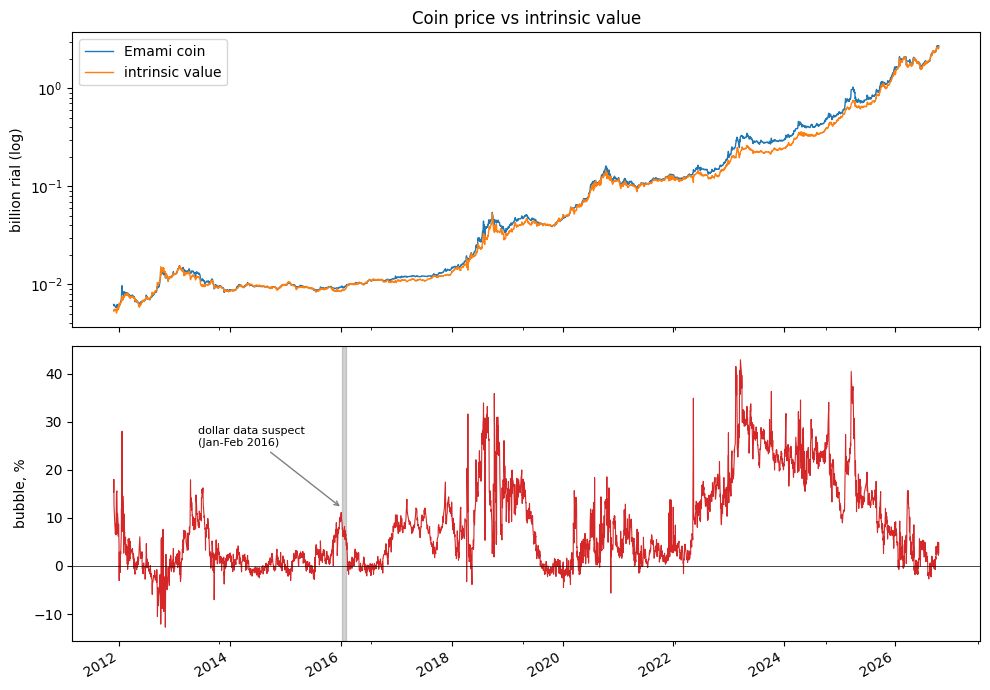

In [6]:
fig, (a, b) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
(df[["coin", "intrinsic"]] / 1e9).plot(ax=a, logy=True, lw=1)
a.set_ylabel("billion rial (log)"); a.legend(["Emami coin", "intrinsic value"]); a.set_title("Coin price vs intrinsic value")
(df["bubble"] * 100).plot(ax=b, lw=0.8, color="tab:red")
b.axvspan(*SUSPECT, color="gray", alpha=0.35)
b.annotate("dollar data suspect\n(Jan-Feb 2016)", xy=(SUSPECT[0], 12), xytext=(pd.Timestamp("2013-06-01"), 25),
           fontsize=8, arrowprops=dict(arrowstyle="->", color="gray"))
b.axhline(0, color="k", lw=0.5); b.set_ylabel("bubble, %"); b.set_xlabel("")
plt.tight_layout(); plt.savefig(ROOT / "images" / "coin-bubble.png", dpi=130); plt.show()

In [7]:
print(df["bubble"].describe().round(3).to_string())
yearly = df["bubble"].groupby(df.index.year).agg(["mean", "min", "max"]).round(3)
yearly

count    3840.000
mean        0.084
std         0.091
min        -0.127
25%         0.013
50%         0.054
75%         0.139
max         0.429


,mean,min,max
date,,,
2011,0.100,0.047,0.180
2012,0.001,-0.127,0.280
2013,0.051,-0.070,0.179
2014,0.003,-0.025,0.042
2015,0.018,-0.030,0.102
2016,0.022,-0.021,0.111
2017,0.086,0.017,0.174
2018,0.137,-0.039,0.358
2019,0.067,-0.025,0.200


میانگین حباب حدود ۸٪ است، ولی از نزدیک صفر (۱۳۹۳) تا بیش از ۴۰٪ (۱۴۰۲) تغییر می‌کند. یعنی «حباب عادی» یک عدد ثابت نیست و به دوره بستگی دارد.

## ۳. آیا حباب به میانگین برمی‌گردد؟

اگر سکه خیلی گران شود، آربیتراژگرها می‌توانند طلا را بخرند، سکه بسازند و بفروشند؛ پس انتظار داریم حباب از یک حدی بالاتر نماند. این را با یک مدل ساده AR(1) می‌سنجیم:

`bubble_t = c + φ · bubble_{t-1} + ε`

اگر φ نزدیک ۱ باشد، حباب مثل قدم‌زدن تصادفی (random walk) است و برنمی‌گردد. اگر φ کمتر از ۱ باشد، برمی‌گردد و **نیمه‌عمر** آن برابر `ln(0.5)/ln(φ)` روز است.

In [8]:
def ar1_phi(x):
    x = np.asarray(x)
    a, b = x[:-1], x[1:]
    a0 = a - a.mean()
    return (a0 * (b - b.mean())).sum() / (a0 ** 2).sum()

def half_life(phi):
    return np.log(0.5) / np.log(phi) if 0 < phi < 1 else np.nan

for label, s in [("all", df["bubble"]), ("2011-2019", df["bubble"][:"2019"]), ("2020-2026", df["bubble"]["2020":])]:
    phi = ar1_phi(s)
    print(f"{label:10s} n={len(s):5d}  phi={phi:.4f}  half-life={half_life(phi):5.1f} days")

all        n= 3840  phi=0.9656  half-life= 19.8 days
2011-2019  n= 1945  phi=0.9363  half-life= 10.5 days
2020-2026  n= 1895  phi=0.9705  half-life= 23.2 days


### آیا φ واقعاً از قدم‌زدن تصادفی کمتر است؟
برآورد φ در نمونه محدود حتی برای یک random walk هم کمی کمتر از ۱ درمی‌آید. پس φ را با **شبیه‌سازی** مقایسه می‌کنیم: تغییرات روزانه حباب را به‌هم می‌ریزیم (که هر ساختار برگشت را از بین می‌برد)، حباب تصادفی می‌سازیم و φ آن را حساب می‌کنیم.

In [9]:
rng = np.random.default_rng(42)
diffs = df["bubble"].diff().dropna().to_numpy()
n = len(df)
null = np.array([ar1_phi(np.cumsum(rng.choice(diffs, n))) for _ in range(2000)])
obs = ar1_phi(df["bubble"])
print(f"observed phi        : {obs:.4f}")
print(f"random-walk phi     : mean {null.mean():.4f}, 5th percentile {np.percentile(null, 5):.4f}")
print(f"share of null <= obs: {(null <= obs).mean():.4f}")

observed phi        : 0.9656
random-walk phi     : mean 0.9987, 5th percentile 0.9965
share of null <= obs: 0.0000


φ مشاهده‌شده (حدود ۰٫۹۶۶) خیلی کمتر از بازه random walk (حدود ۰٫۹۹۶ به بالا) است. پس حباب شواهد روشنی از **برگشت** نشان می‌دهد، با نیمه‌عمر حدود ۲۰ روز. (به محدودیت‌های بخش بعد توجه کن: این برگشت به کدام سطح است؟)

## ۴. چه چیزی ممکن است این نتیجه را خراب کند؟

۱. **نویز اندازه‌گیری:** قیمت سکه، دلار و اونس هم‌زمان ثبت نمی‌شوند. نویز مستقل، تغییرات حباب را منفی‌همبسته می‌کند و φ را به‌طور کاذب پایین می‌آورد. یعنی نیمه‌عمر ۲۰ روزه می‌تواند کمی **خوش‌بینانه** باشد.
۲. **نیمه‌عمر ثابت نیست و میانگین هم ثابت نیست:** نیمه‌عمر بسته به دوره ۱۰ تا ۲۳ روز است. نمودار هم نشان می‌دهد حباب سال‌ها در یک «سطح» می‌ماند (مثلاً ۱۴۰۲ تا ۱۴۰۳ حدود ۲۰ تا ۳۰ درصد). پس φ احتمالاً بازگشت **نوسان‌های کوتاه‌مدت به یک سطح آهسته‌متغیر** را می‌سنجد، نه بازگشت به یک عدد ثابت مثل ۸٪. این عدد را به‌عنوان یک ویژگی ثابت بازار نگیر.
۳. **«حباب» فقط پریمیوم است:** شامل هزینه ضرب، نقدشوندگی، تقاضای روانی و ریسک بازار هم می‌شود، نه صرفاً حباب.
۴. **منبع داده:** TGJU غیررسمی است. فقط طلا در کل دوره و دلار و سکه از ۲۰۲۱ به بعد (روی نمونه) با منبع دوم تأیید شده‌اند.

حساسیت به زمان‌بندی را با استفاده از قیمت اونس **روز قبل** می‌سنجیم:

In [10]:
bubble_prev = df["coin"] / (df["ons"].shift(1).bfill() / GRAMS_PER_OUNCE * PURE_GOLD_G * df["usd"]) - 1
print("correlation with main bubble :", round(df["bubble"].corr(bubble_prev), 4))
print("mean abs difference          :", f"{(df['bubble'] - bubble_prev).abs().mean():.2%}")
print("phi with previous-day ounce  :", round(ar1_phi(bubble_prev), 4))

correlation with main bubble : 0.9929
mean abs difference          : 0.68%
phi with previous-day ounce  : 0.9636


### قیمت‌های منجمد
در بعضی دوره‌ها قیمت دلار یا سکه چند روز پشت‌هم تقریباً بدون تغییر مانده (بازار بسته یا قیمت قدیمی). در آن روزها اونس حرکت می‌کند ولی قیمت ایرانی نه، پس حباب محاسبه‌شده ساختگی است. روزهایی را که قیمت دلار یا سکه **۴ روز یا بیشتر** با تغییر کمتر از ۰٫۰۵٪ ثابت مانده، به‌علاوه پنجره «دلار مشکوک» ۲۰۱۶-۰۱-۰۹ تا ۲۰۱۶-۰۲-۰۴ (در نمودار بالا خاکستری شده) کنار می‌گذاریم و دوباره φ را می‌سنجیم.

In [11]:
def frozen(series, tol=0.0005, min_days=4):
    s = series.dropna()
    run_id = (s.pct_change().abs() > tol).cumsum()
    size = s.groupby(run_id).transform("size")
    return (size >= min_days).reindex(df.index, fill_value=False)

stale = frozen(usd.close) | frozen(coin.close)
clean = df.loc[~stale & ~df["suspect"], "bubble"]
print(f"frozen days dropped: {stale.sum()}, suspect-dollar days dropped: {df.suspect.sum()} (of {len(df)})")
print("\nphi, all days    :", round(ar1_phi(df["bubble"]), 4))
print("phi, without them:", round(ar1_phi(clean), 4), " half-life", round(half_life(ar1_phi(clean)), 1), "days")
print("mean bubble, all vs without:", round(df["bubble"].mean(), 4), round(clean.mean(), 4))

frozen days dropped: 164, suspect-dollar days dropped: 20 (of 3840)

phi, all days    : 0.9656
phi, without them: 0.9657  half-life 19.8 days
mean bubble, all vs without: 0.084 0.0845


نتیجه تغییری نکرد: φ با و بدون این روزها یکی است (حدود ۰٫۹۶۶)، پس قیمت‌های منجمد نتیجه را خراب نمی‌کنند. این روزها حدود ۴٪ نمونه‌اند و بیشترشان در ۲۰۲۶ (۴۷ روز) و ۲۰۱۵ (۴۲ روز) هستند.

با اونس روز قبل هم نتیجه تقریباً همان است (همبستگی بالای ۰٫۹۹)، پس انتخاب زمان‌بندی نتیجه را عوض نمی‌کند.

## جمع‌بندی

- حباب سکه امامی در حدود ۱۵ سال گذشته (از آذر ۱۳۹۰) میانگین حدود ۸٪ داشته و بین حدود ۱۳- تا ۴۳+ درصد تغییر کرده است.
- انحراف‌های کوتاه‌مدت حباب برمی‌گردند (نیمه‌عمر حدود ۲۰ روز، با تفاوت زیاد بین دوره‌ها)، ولی سطح حباب خودش سال‌ها جابه‌جا می‌شود. پس «برگشت به میانگین ثابت» را نمی‌توان نتیجه گرفت.
- این یک **اندازه‌گیری گذشته** است. نمی‌گوید حباب فردا چقدر است و نمی‌گوید معامله‌ای سودآور است. برای ساخت استراتژی باید هزینه معامله، نقدشوندگی، ریسک نگهداری و دسترسی واقعی به ساخت یا انحلال سکه در نظر گرفته شود؛ هیچ‌کدام در این نوت‌بوک نیست.

**گام بعدی:** پیدا کردن منبع دوم برای ایران قبل از ۲۰۲۱ و روشن کردن ماجرای اسفند ۱۴۰۴، مدل کردن سطح آهسته‌متغیر حباب (مثلاً میانگین متحرک)، و بررسی رابطه اندازه حباب با نوسان دلار.